In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE

In [ ]:
df = pd.read_csv("winequality.csv")

In [ ]:
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [ ]:
print(f"Dataset Shape: {df.shape}")
print(f"Class Distribution:\n{df['quality'].value_counts().sort_index()}")

Dataset Shape: (6497, 13)
Class Distribution:
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


In [ ]:
df = pd.get_dummies(df, columns=['type'], drop_first=True, dtype=int)


for col in df.columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mean())

In [ ]:
X = df.drop(columns=['quality'])
y = df['quality']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [ ]:
sch = StandardScaler()
X_train_scaled = sch.fit_transform(X_train)
X_test_scaled = sch.transform(X_test)

In [ ]:
smote = SMOTE(random_state=42, k_neighbors=3)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

In [ ]:
clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    criterion='entropy',
    random_state=42,
    n_jobs=-1
)
clf.fit(X_train_res, y_train_res)

RandomForestClassifier(criterion='entropy', max_depth=15, n_estimators=300,
                       n_jobs=-1, random_state=42)

In [ ]:
y_pred = clf.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
print("\n" + "="*40)
print(f"Overall Accuracy: {acc * 100:.2f}%")
print("="*40)


Overall Accuracy: 66.54%


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.45      0.35      0.39        43
           5       0.69      0.78      0.73       428
           6       0.71      0.64      0.67       567
           7       0.59      0.63      0.61       216
           8       0.46      0.41      0.43        39
           9       0.00      0.00      0.00         1

    accuracy                           0.67      1300
   macro avg       0.41      0.40      0.41      1300
weighted avg       0.66      0.67      0.66      1300



In [ ]:
print("\nConfusion Matrix:")
print(pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=[f"Actual {c}" for c in sorted(y.unique())],
    columns=[f"Pred {c}" for c in sorted(y.unique())]
))


Confusion Matrix:
          Pred 3  Pred 4  Pred 5  Pred 6  Pred 7  Pred 8  Pred 9
Actual 3       0       2       2       1       0       1       0
Actual 4       0      15      18       8       2       0       0
Actual 5       1       9     335      79       4       0       0
Actual 6       1       6     120     362      71       7       0
Actual 7       0       1      10      57     137      10       1
Actual 8       0       0       0       4      19      16       0
Actual 9       0       0       0       0       0       1       0


In [ ]:
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nFeature Importances:")
print(importances.to_string(index=False))


Feature Importances:
             Feature  Importance
           chlorides    0.128921
             alcohol    0.128310
 free sulfur dioxide    0.102479
    volatile acidity    0.102359
       fixed acidity    0.087203
                  pH    0.082143
total sulfur dioxide    0.080329
             density    0.078122
         citric acid    0.075411
           sulphates    0.066710
      residual sugar    0.060952
          type_white    0.007061


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
cm=confusion_matrix(y_test,y_pred)

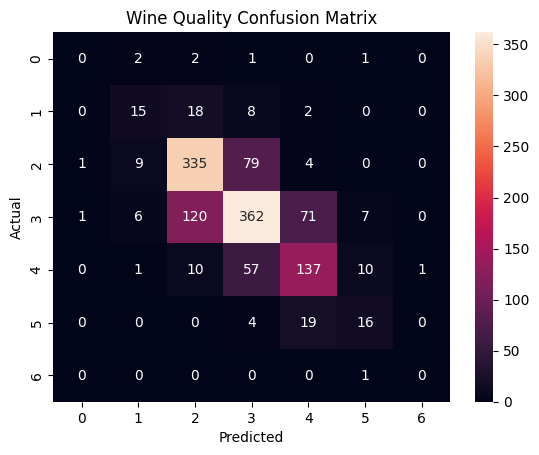

In [ ]:
sns.heatmap(cm,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Wine Quality Confusion Matrix")
plt.show()